# Dataset Quality and Analysis for Soccer Ball Detection

This notebook is the dataset-quality portion of our DATA 4620 final project. Our primary goal is to improve **soccer-ball detection**. Player and referee annotations are included only to describe class imbalance and may be used as a later extension.

This notebook does **not** train YOLO and does **not** create a new random split. It uses the same saved train/validation manifests created in `02_baseline_yolo.ipynb` when those files are available. The original `images/val` folder remains the protected final test set.


## Before running

Upload or unzip the `Football-Image-Dataset-main` folder into Colab so that it contains `data.yaml`, `images/`, and `labels/`. Also copy your partner's `results/baseline/splits/train.txt` and `val.txt` files into the same dataset folder if you want the internal-split analysis to match the baseline model exactly.

If the dataset is already in `/content/Football-Image-Dataset-main`, no path change is needed below.


In [3]:
!git clone https://github.com/skaczylo/Football-Image-Dataset.git

fatal: destination path 'Football-Image-Dataset' already exists and is not an empty directory.


In [4]:
!ls /content/Football-Image-Dataset

data.yaml  images  labels  LICENSE  README.md


In [5]:
from collections import Counter
from pathlib import Path
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageDraw
from IPython.display import display, Markdown

plt.rcParams['figure.dpi'] = 120
SEED = 4620
TARGET_IMAGE_SIZE = 640
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png'}

# Change this only if your extracted dataset folder has a different name.
DATASET_ROOT = Path('/content/Football-Image-Dataset-main')

# If the default folder was not found, automatically use the only data.yaml under /content.
if not (DATASET_ROOT / 'data.yaml').exists():
    candidates = list(Path('/content').rglob('data.yaml'))
    if len(candidates) == 1:
        DATASET_ROOT = candidates[0].parent
    else:
        raise FileNotFoundError(
            'Could not find one dataset root. Upload/extract the Football-Image-Dataset folder, '            'then set DATASET_ROOT to the folder containing data.yaml.'
        )

with open(DATASET_ROOT / 'data.yaml', encoding='utf-8') as file:
    config = yaml.safe_load(file)

CLASS_NAMES = {int(key): str(value) for key, value in config['names'].items()}
BALL_CLASS_ID = next(class_id for class_id, name in CLASS_NAMES.items()
                     if name.strip().lower() in {'ball', 'soccer ball', 'football'})
COLORS = {0: 'red', 1: 'lime', 2: 'cyan'}
OUTPUT_DIR = DATASET_ROOT / 'results' / 'dataset_quality'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Dataset root:', DATASET_ROOT)
print('Classes:', CLASS_NAMES)
print('Primary project class:', CLASS_NAMES[BALL_CLASS_ID])


Dataset root: /content/Football-Image-Dataset
Classes: {0: 'ball', 1: 'player', 2: 'referee'}
Primary project class: ball


## 1. Inventory images and labels

This checks that every image has a matching YOLO label file and records dataset dimensions. It also stores every valid annotation for the later quality checks.


In [6]:
SPLITS = ('train', 'val')
images_by_split = {}
labels_by_split = {}

for split in SPLITS:
    image_folder = DATASET_ROOT / 'images' / split
    label_folder = DATASET_ROOT / 'labels' / split
    images_by_split[split] = sorted(
        path for path in image_folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    labels_by_split[split] = sorted(label_folder.glob('*.txt'))

print('Image and label inventory')
for split in SPLITS:
    print(f'{split:>5}: {len(images_by_split[split])} images, {len(labels_by_split[split])} label files')
print('Total images:', sum(map(len, images_by_split.values())))


Image and label inventory
train: 512 images, 512 label files
  val: 100 images, 100 label files
Total images: 612


The dataset contains **612 images**: 512 in the repository's training partition and 100 in its original validation partition. Every image has one corresponding label file, so there are no missing image-label pairs. The original 100-image validation partition should stay protected and be used only for the group's final model evaluation.


## 2. Structural label validation and boundary-box audit

YOLO labels should contain five values: class ID, x-center, y-center, width, and height. Bounding boxes that extend beyond an image edge are saved as **warnings** for visual review; they are not automatically deleted because they may describe partially visible objects.


In [7]:
def label_path_for(image_path):
    return DATASET_ROOT / 'labels' / image_path.parent.name / f'{image_path.stem}.txt'

issues = []
edge_records = []
empty_labels = []
annotations = []
image_sizes = {}

for split in SPLITS:
    image_stems = {path.stem: path for path in images_by_split[split]}
    label_stems = {path.stem: path for path in labels_by_split[split]}
    for stem in sorted(image_stems.keys() - label_stems.keys()):
        issues.append({'type': 'missing_label', 'split': split, 'file': stem, 'line': None})
    for stem in sorted(label_stems.keys() - image_stems.keys()):
        issues.append({'type': 'missing_image', 'split': split, 'file': stem, 'line': None})

    for stem in sorted(image_stems.keys() & label_stems.keys()):
        image_path = image_stems[stem]
        label_path = label_stems[stem]
        try:
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image_width, image_height = image.size
        except Exception as error:
            issues.append({'type': 'unreadable_image', 'split': split, 'file': image_path.name,
                           'line': None, 'details': str(error)})
            continue

        image_sizes[image_path] = (image_width, image_height)
        lines = [line.strip() for line in label_path.read_text().splitlines() if line.strip()]
        if not lines:
            empty_labels.append(label_path)

        for line_number, line in enumerate(lines, start=1):
            parts = line.split()
            record_base = {'split': split, 'image_path': image_path, 'label_path': label_path,
                           'line': line_number, 'raw': line}
            if len(parts) != 5:
                issues.append({**record_base, 'type': 'wrong_value_count'})
                continue
            try:
                class_id = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:])
            except ValueError:
                issues.append({**record_base, 'type': 'non_numeric'})
                continue
            values = (x_center, y_center, width, height)
            if class_id not in CLASS_NAMES:
                issues.append({**record_base, 'type': 'unknown_class'})
                continue
            if not all(np.isfinite(values)):
                issues.append({**record_base, 'type': 'non_finite_coordinate'})
                continue
            if not all(0 <= value <= 1 for value in values) or width <= 0 or height <= 0:
                issues.append({**record_base, 'type': 'invalid_coordinate'})
                continue

            annotation = {**record_base, 'class_id': class_id, 'x_center': x_center,
                          'y_center': y_center, 'width_norm': width, 'height_norm': height,
                          'image_width': image_width, 'image_height': image_height,
                          'width_px': width * image_width, 'height_px': height * image_height,
                          'area_norm': width * height,
                          'area_px': width * image_width * height * image_height}
            annotations.append(annotation)
            crosses_edge = (x_center - width / 2 < 0 or x_center + width / 2 > 1 or
                            y_center - height / 2 < 0 or y_center + height / 2 > 1)
            if crosses_edge:
                edge_records.append(annotation)

annotations_df = pd.DataFrame(annotations)
issue_types = Counter(issue['type'] for issue in issues)
print('Valid annotations:', len(annotations_df))
print('Structural issues:', dict(issue_types) if issues else 'None')
print('Boundary-crossing box warnings:', len(edge_records))
print('Empty label files (intentional background images):', len(empty_labels))
print('Image dimensions:', dict(Counter(image_sizes.values())))


Valid annotations: 10136
Structural issues: None
Boundary-crossing box warnings: 19
Empty label files (intentional background images): 1
Image dimensions: {(1920, 1080): 548, (1280, 720): 44, (854, 480): 3, (640, 360): 17}


The structural validation shows that the dataset is ready for training. All **10,136 annotations** have valid class IDs and numeric coordinates, and no unreadable images or missing labels were found. The one empty label file is a legitimate background image and should remain in the training data.

The audit found **19 boundary-crossing boxes**. These are warnings, not automatically invalid labels: they can occur when a person is partly outside the camera frame. The next visualization is used to decide whether they should be retained.


## 3. Visual review of boundary-crossing annotations

Review these images before making a recommendation. A magenta box is the annotation that crosses an image edge; thin colored boxes show the other labels. In the final report, describe these as retained warnings if they represent normal partial objects rather than annotation mistakes.


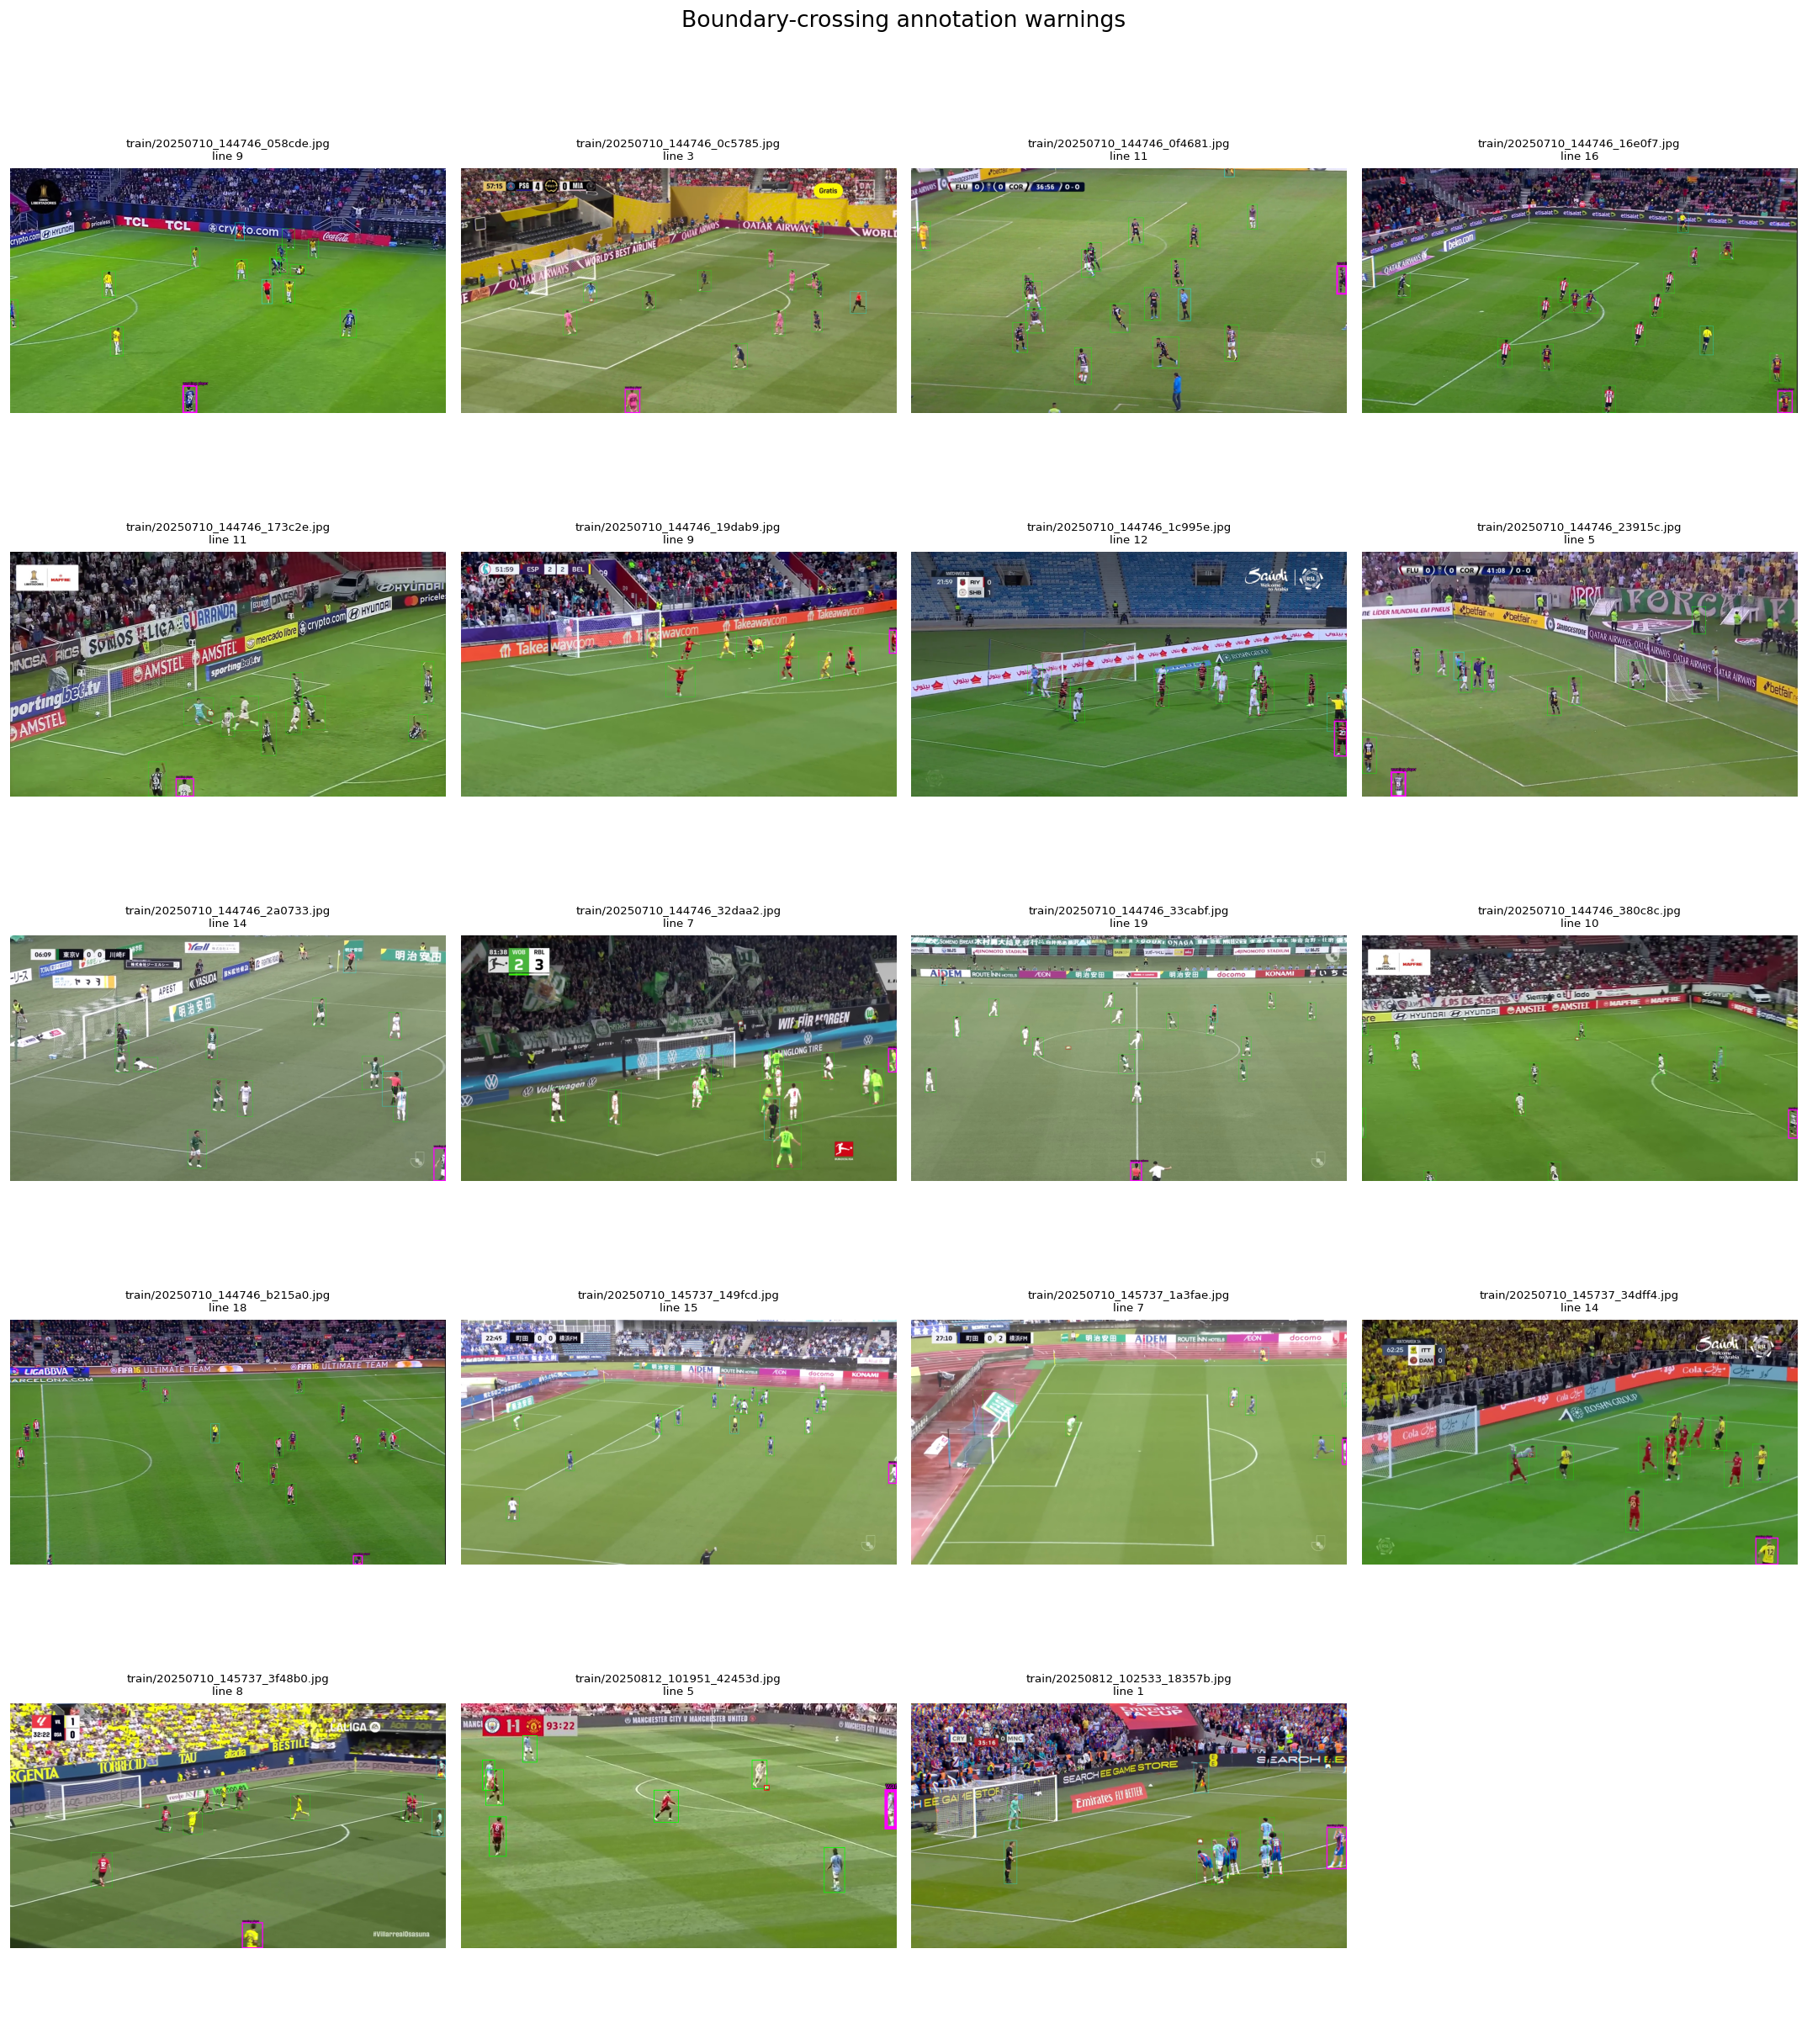

In [8]:
def load_yolo_boxes(label_path):
    boxes = []
    for line in label_path.read_text().splitlines():
        if line.strip():
            class_id, x, y, width, height = line.split()
            boxes.append((int(class_id), *map(float, (x, y, width, height))))
    return boxes

def draw_box(draw, box, image_width, image_height, color, width=3, label=None):
    _, x, y, bw, bh = box
    x1, y1 = (x - bw / 2) * image_width, (y - bh / 2) * image_height
    x2, y2 = (x + bw / 2) * image_width, (y + bh / 2) * image_height
    draw.rectangle((x1, y1, x2, y2), outline=color, width=width)
    if label:
        draw.text((max(0, x1 + 2), max(0, y1 - 12)), label, fill=color, stroke_width=1, stroke_fill='black')

columns = 4
rows = int(np.ceil(len(edge_records) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(18, max(4, 4 * rows)))
axes = np.ravel(axes)

for axis, record in zip(axes, edge_records):
    image = Image.open(record['image_path']).convert('RGB')
    draw = ImageDraw.Draw(image)
    image_width, image_height = image.size
    for class_id, x, y, bw, bh in load_yolo_boxes(record['label_path']):
        draw_box(draw, (class_id, x, y, bw, bh), image_width, image_height, COLORS[class_id], width=1)
    highlighted = (record['class_id'], record['x_center'], record['y_center'],
                   record['width_norm'], record['height_norm'])
    draw_box(draw, highlighted, image_width, image_height, 'magenta', width=5,
             label=f'warning: {CLASS_NAMES[record["class_id"]]}')
    axis.imshow(image)
    axis.set_title(f'{record["split"]}/{record["image_path"].name}\nline {record["line"]}', fontsize=8)
    axis.axis('off')

for axis in axes[len(edge_records):]:
    axis.axis('off')

fig.suptitle('Boundary-crossing annotation warnings', fontsize=16, y=1.01)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'boundary_crossing_audit.png', bbox_inches='tight')
plt.show()


In this figure, the thick magenta box is the annotation that crosses an image edge. The warnings appear to be mostly players or referees who are partially cropped by the camera at the bottom or side of the frame. Because the boxes still correspond to real visible people, the recommended action is to **retain the labels** and report them as a minor dataset limitation rather than delete or alter them. These warnings are also not central to the project's primary task of soccer-ball detection.


## 4. Class imbalance

The project evaluates soccer-ball detection first. This chart shows why reporting only an overall detection score would be misleading: player annotations greatly outnumber ball annotations.


,Class,Boxes,Percent of all boxes
0,ball,500,4.9%
1,player,"8,844",87.3%
2,referee,792,7.8%


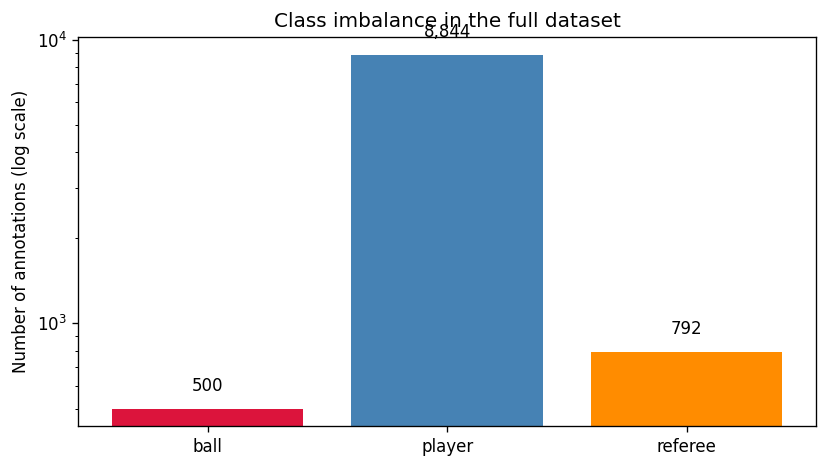

There are 17.7 player annotations for every ball annotation.


In [9]:
class_counts = annotations_df['class_id'].value_counts().reindex(sorted(CLASS_NAMES), fill_value=0)
class_summary = pd.DataFrame({
    'Class': [CLASS_NAMES[class_id] for class_id in class_counts.index],
    'Boxes': class_counts.to_numpy(),
})
class_summary['Percent of all boxes'] = 100 * class_summary['Boxes'] / class_summary['Boxes'].sum()
display(class_summary.style.format({'Boxes': '{:,.0f}', 'Percent of all boxes': '{:.1f}%'}))

fig, axis = plt.subplots(figsize=(7, 4))
bars = axis.bar(class_summary['Class'], class_summary['Boxes'], color=['crimson', 'steelblue', 'darkorange'])
axis.set_yscale('log')
axis.set_ylabel('Number of annotations (log scale)')
axis.set_title('Class imbalance in the full dataset')
for bar, count in zip(bars, class_summary['Boxes']):
    axis.text(bar.get_x() + bar.get_width() / 2, count * 1.12, f'{count:,}', ha='center', va='bottom')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'class_imbalance.png', bbox_inches='tight')
plt.show()

player_to_ball = class_counts[1] / class_counts[BALL_CLASS_ID]
print(f'There are {player_to_ball:.1f} player annotations for every ball annotation.')


The dataset is strongly imbalanced. Soccer balls account for only **500 labels (4.9%)**, while players account for **8,844 labels (87.3%)**. There are about **17.7 player annotations for every ball annotation**. Therefore, a strong overall detection score could hide weak ball detection. The baseline and improved models should be compared primarily using **ball precision, ball recall, and ball mAP**, rather than an overall score alone.


## 5. Soccer-ball size analysis

The plots below measure the actual size of labeled balls. The estimated 640-pixel measurement assumes aspect-ratio-preserving resizing without upscaling, so it is a useful approximation of how much visual detail the detector receives.


,min,10%,25%,50%,75%,90%,max
area_norm,0.000,0.000,0.000,0.000,0.000,0.000,0.006
area_px,36.298,131.947,199.951,293.516,416.302,594.757,12155.215
width_px,6.031,11.664,14.265,17.560,21.132,25.789,83.019
height_px,4.260,11.169,13.463,16.709,20.122,24.140,146.415
area_at_640,4.033,18.762,24.708,36.560,50.879,68.737,1350.579
max_side_at_640,2.556,4.569,5.177,6.459,7.668,9.171,48.805


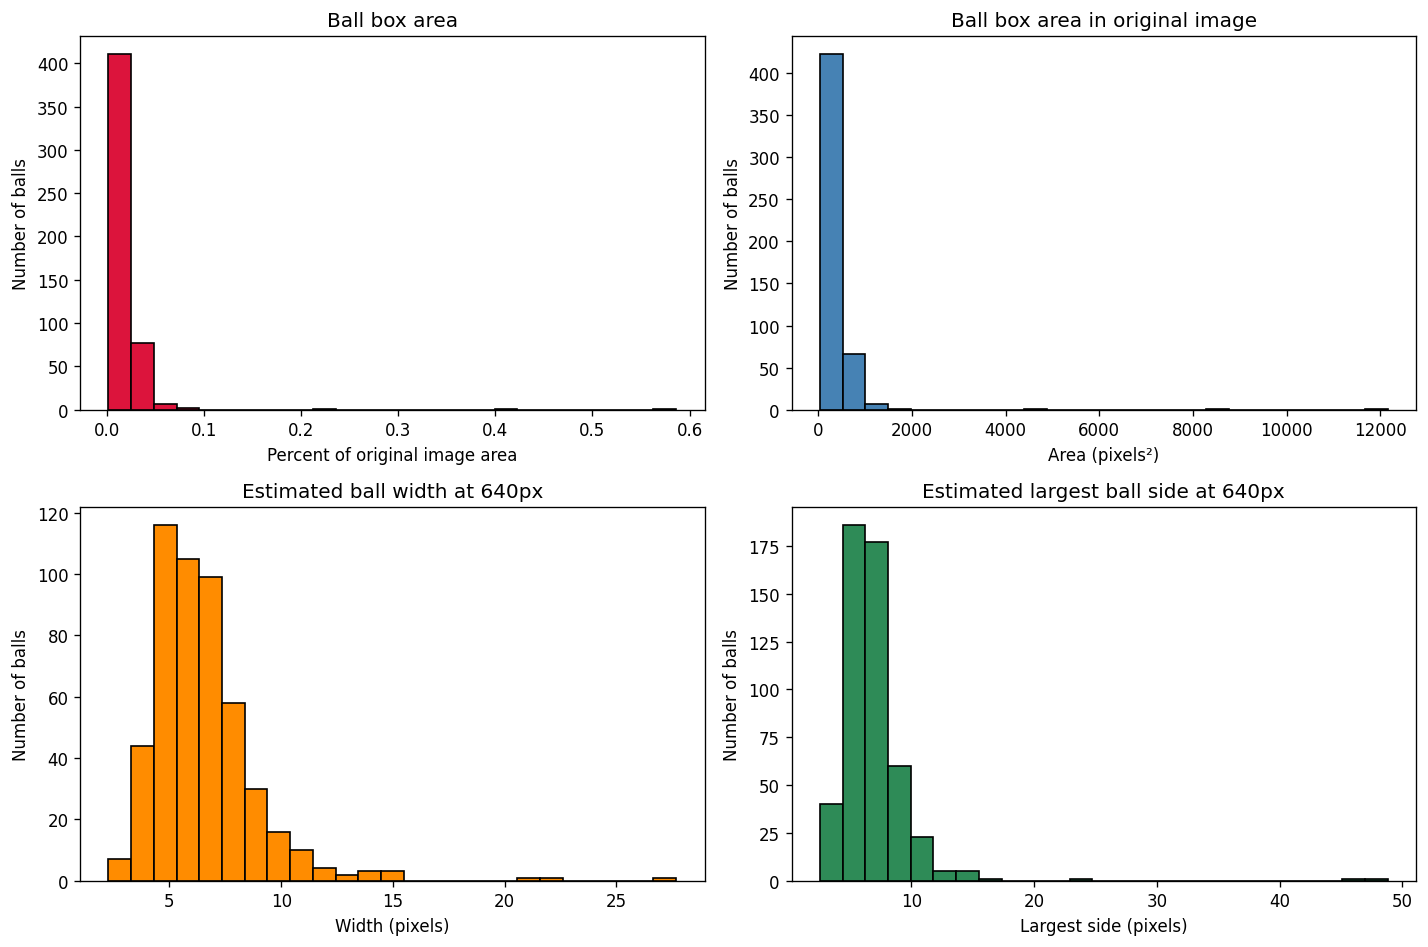

,Estimated largest side at 640px,Ball boxes,Percent
0,≤ 8 px,394,78.8%
1,8–16 px,103,20.6%
2,16–32 px,1,0.2%
3,> 32 px,2,0.4%


In [10]:
ball_df = annotations_df[annotations_df['class_id'] == BALL_CLASS_ID].copy()
scale_to_640 = np.minimum(TARGET_IMAGE_SIZE / ball_df['image_width'], TARGET_IMAGE_SIZE / ball_df['image_height'])
scale_to_640 = np.minimum(scale_to_640, 1.0)  # conservative estimate: do not assume small images are enlarged
ball_df['width_at_640'] = ball_df['width_px'] * scale_to_640
ball_df['height_at_640'] = ball_df['height_px'] * scale_to_640
ball_df['area_at_640'] = ball_df['width_at_640'] * ball_df['height_at_640']
ball_df['max_side_at_640'] = np.maximum(ball_df['width_at_640'], ball_df['height_at_640'])

summary = ball_df[['area_norm', 'area_px', 'width_px', 'height_px', 'area_at_640', 'max_side_at_640']].describe(
    percentiles=[.1, .25, .5, .75, .9]
).T
display(summary[['min', '10%', '25%', '50%', '75%', '90%', 'max']].style.format('{:.3f}'))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(ball_df['area_norm'] * 100, bins=25, edgecolor='black', color='crimson')
axes[0, 0].set(title='Ball box area', xlabel='Percent of original image area', ylabel='Number of balls')
axes[0, 1].hist(ball_df['area_px'], bins=25, edgecolor='black', color='steelblue')
axes[0, 1].set(title='Ball box area in original image', xlabel='Area (pixels²)', ylabel='Number of balls')
axes[1, 0].hist(ball_df['width_at_640'], bins=25, edgecolor='black', color='darkorange')
axes[1, 0].set(title='Estimated ball width at 640px', xlabel='Width (pixels)', ylabel='Number of balls')
axes[1, 1].hist(ball_df['max_side_at_640'], bins=25, edgecolor='black', color='seagreen')
axes[1, 1].set(title='Estimated largest ball side at 640px', xlabel='Largest side (pixels)', ylabel='Number of balls')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'ball_size_analysis.png', bbox_inches='tight')
plt.show()

size_bins = [-np.inf, 8, 16, 32, np.inf]
size_labels = ['≤ 8 px', '8–16 px', '16–32 px', '> 32 px']
bucket_counts = pd.cut(ball_df['max_side_at_640'], bins=size_bins, labels=size_labels).value_counts().reindex(size_labels)
bucket_summary = pd.DataFrame({'Estimated largest side at 640px': size_labels, 'Ball boxes': bucket_counts.to_numpy()})
bucket_summary['Percent'] = 100 * bucket_summary['Ball boxes'] / len(ball_df)
display(bucket_summary.style.format({'Ball boxes': '{:,.0f}', 'Percent': '{:.1f}%'}))


The ball-size results explain why this is a difficult object-detection problem. The median original ball box is only about **17.6 pixels wide by 16.7 pixels high**. After resizing toward a 640-pixel YOLO input, its median largest side is only about **6.5 pixels**.

Most importantly, **394 of 500 balls (78.8%)** have an estimated largest side of 8 pixels or less at 640px. This gives a clear reason to test a higher-resolution model: a larger input may preserve more visual information for these tiny balls. The few large boxes in the right tail of the plots are likely closer or zoomed-in ball views and do not represent the typical example.


## 6. Capture sessions and possible leakage

This reproduces the near-duplicate check used by the baseline notebook. It also shows how images are concentrated within capture sessions. A hash-based check can prevent extremely similar frames from crossing the internal split, but it cannot prove that frames from the same source video are independent.


,Capture session,Images
0,20250710_144746,276
1,20250710_145737,194
3,20250812_101951,14
14,20250812_103121,6
6,20250812_102038,5
7,20250812_102039,4
2,20250812_101950,3
10,20250812_102528,3
4,20250812_102022,1
5,20250812_102037,1


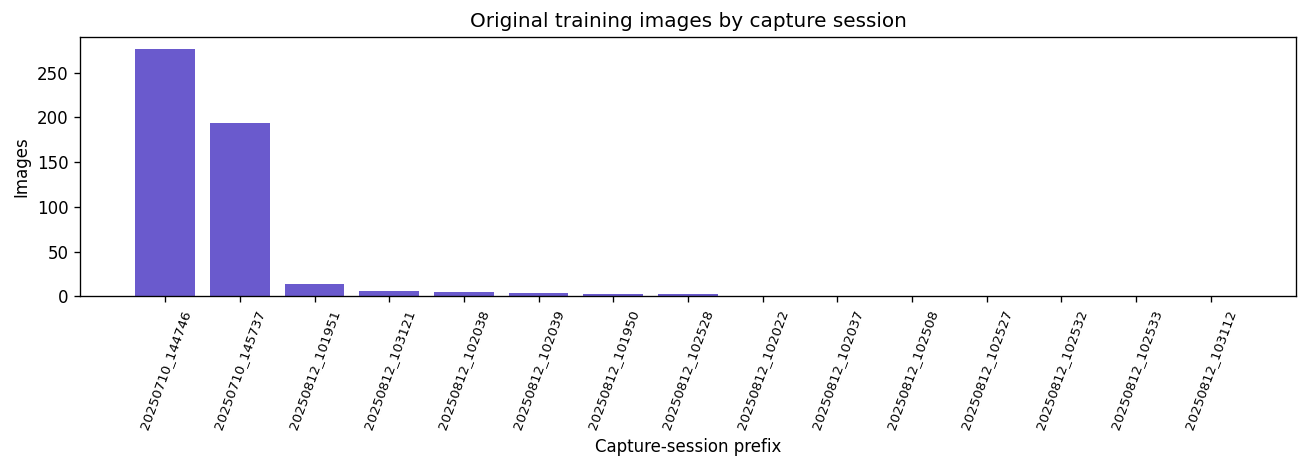

Near-duplicate visual groups: 503
Largest visual group: 2 images
Groups with more than one image: 9


In [11]:
def source_prefix(path):
    parts = path.stem.rsplit('_', 1)
    return parts[0] if len(parts) == 2 and len(parts[1]) == 6 else path.stem

source_images = images_by_split['train']
session_counts = Counter(source_prefix(path) for path in source_images)
session_df = pd.DataFrame(session_counts.items(), columns=['Capture session', 'Images']).sort_values('Images', ascending=False)
display(session_df)

fig, axis = plt.subplots(figsize=(11, 4))
axis.bar(session_df['Capture session'], session_df['Images'], color='slateblue')
axis.set(title='Original training images by capture session', xlabel='Capture-session prefix', ylabel='Images')
axis.tick_params(axis='x', rotation=70, labelsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'capture_sessions.png', bbox_inches='tight')
plt.show()

def difference_hash(path, size=8):
    with Image.open(path) as image:
        pixels = np.asarray(image.convert('L').resize((size + 1, size)))
    bits = (pixels[:, 1:] > pixels[:, :-1]).ravel()
    return sum(int(bit) << i for i, bit in enumerate(bits))

hashes = [difference_hash(path) for path in source_images]
parent = list(range(len(source_images)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(a, b):
    a, b = find(a), find(b)
    if a != b:
        parent[b] = a

for i in range(len(hashes)):
    for j in range(i):
        if (hashes[i] ^ hashes[j]).bit_count() <= 6:
            union(i, j)

visual_groups = {}
for index, path in enumerate(source_images):
    visual_groups.setdefault(find(index), []).append(path)
groups = list(visual_groups.values())
print(f'Near-duplicate visual groups: {len(groups)}')
print(f'Largest visual group: {max(map(len, groups))} images')
print('Groups with more than one image:', sum(len(group) > 1 for group in groups))


The near-duplicate check is encouraging: there are **503 visual groups** among 512 source-training images, the largest group contains only two images, and only nine groups contain more than one image. This means the dataset does not appear to have many nearly identical frames.

However, the capture-session chart shows that two sessions contain **470 of the 512 original training images**, about **92%** of the source-training partition. Images from the same session can still share camera angles, lighting, and other visual characteristics even when they are not near duplicates. This should be reported as a limitation: internal validation may be somewhat optimistic because complete session independence cannot be guaranteed.


## 7. Confirm the baseline model's split, when manifests are available

This is a verification only. It does not create a new split. If the files are missing, copy `results/baseline/splits/train.txt` and `val.txt` from your partner's project folder into the same location in Colab.


In [12]:
split_dir = DATASET_ROOT / 'results' / 'baseline' / 'splits'
train_manifest = split_dir / 'train.txt'
val_manifest = split_dir / 'val.txt'

if train_manifest.exists() and val_manifest.exists():
    train_names = {Path(line.strip()).name for line in train_manifest.read_text().splitlines() if line.strip()}
    val_names = {Path(line.strip()).name for line in val_manifest.read_text().splitlines() if line.strip()}
    assert not (train_names & val_names), 'The manifests overlap.'
    print(f'Baseline internal train images: {len(train_names)}')
    print(f'Baseline internal validation images: {len(val_names)}')

    crossing_groups = [group for group in groups
                       if {path.name for path in group} & train_names and {path.name for path in group} & val_names]
    print(f'Near-duplicate groups split across train/validation: {len(crossing_groups)}')

    train_sessions = Counter(source_prefix(path) for path in source_images if path.name in train_names)
    val_sessions = Counter(source_prefix(path) for path in source_images if path.name in val_names)
    shared_sessions = sorted(set(train_sessions) & set(val_sessions))
    print(f'Capture sessions represented in both internal splits: {len(shared_sessions)} of {len(session_counts)}')
    print('Largest shared sessions:', [(session, train_sessions[session], val_sessions[session])
                                       for session in shared_sessions[:5]])
else:
    print('Split manifests were not found. Overall quality analysis is complete, but this check is skipped.')


Split manifests were not found. Overall quality analysis is complete, but this check is skipped.


If this cell says that the manifests were not found, it does **not** mean the dataset analysis failed. It only means the two small files created by your partner's baseline notebook have not yet been copied into this Colab folder:

`results/baseline/splits/train.txt` and `results/baseline/splits/val.txt`

Once those files are available, add them to that location and rerun this section. It will then verify that near-duplicate groups do not cross between your partner's internal training and validation sets.


## 8. Findings and recommendations

Run this final cell after reviewing the boundary-warning grid. The generated text can be copied into the project report and adjusted if visual inspection reveals a clearly incorrect annotation.


In [13]:
ball_share = 100 * len(ball_df) / len(annotations_df)
median_norm_percent = 100 * ball_df['area_norm'].median()
median_area_640 = ball_df['area_at_640'].median()
boundary_recommendation = (
    'Retain the boundary-crossing boxes unless visual inspection identifies a clearly incorrect annotation; '    'they may be legitimate partially visible objects.'
)

findings = f'''### Dataset-quality findings

The dataset contains {sum(len(images_by_split[s]) for s in SPLITS)} images and {len(annotations_df):,} valid annotations. Structural checks found {len(issues)} missing, unreadable, malformed, or out-of-range label problems. One empty training label file is retained as an intentional background image. The audit flagged {len(edge_records)} boxes that cross an image boundary. {boundary_recommendation}

Soccer balls are the primary challenge: the dataset contains {len(ball_df)} ball boxes, representing only {ball_share:.1f}% of all annotations. Their median normalized area is {median_norm_percent:.4f}% of the original image, and their estimated median area at a 640-pixel input is about {median_area_640:.1f} pixels². This supports testing higher-resolution training because small balls may lose important visual detail after resizing.

The dataset is highly imbalanced, with {class_counts[1]:,} player boxes compared with {class_counts[BALL_CLASS_ID]:,} ball boxes. Therefore, the baseline model should be judged primarily with ball precision, recall, and mAP rather than only an overall score.

The near-duplicate analysis found {len(groups)} visual groups, with a largest group of {max(map(len, groups))} images. This reduces concern about exact or nearly identical frames crossing the baseline split. However, the images are concentrated in a small number of capture sessions, so complete independence between training and internal validation cannot be guaranteed. This should be reported as a limitation while keeping the original 100-image validation partition protected for final testing.'''

display(Markdown(findings))

summary = {
    'total_images': int(sum(len(images_by_split[s]) for s in SPLITS)),
    'valid_annotations': int(len(annotations_df)),
    'structural_issues': int(len(issues)),
    'boundary_crossing_warnings': int(len(edge_records)),
    'background_images': int(len(empty_labels)),
    'class_counts': {CLASS_NAMES[int(k)]: int(v) for k, v in class_counts.items()},
    'ball_median_normalized_area': float(ball_df['area_norm'].median()),
    'ball_median_estimated_area_at_640': float(median_area_640),
    'near_duplicate_visual_groups': int(len(groups)),
    'largest_visual_group': int(max(map(len, groups))),
}
(OUTPUT_DIR / 'quality_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(f'Figures and quality_summary.json saved in: {OUTPUT_DIR}')


### Dataset-quality findings

The dataset contains 612 images and 10,136 valid annotations. Structural checks found 0 missing, unreadable, malformed, or out-of-range label problems. One empty training label file is retained as an intentional background image. The audit flagged 19 boxes that cross an image boundary. Retain the boundary-crossing boxes unless visual inspection identifies a clearly incorrect annotation; they may be legitimate partially visible objects.

Soccer balls are the primary challenge: the dataset contains 500 ball boxes, representing only 4.9% of all annotations. Their median normalized area is 0.0159% of the original image, and their estimated median area at a 640-pixel input is about 36.6 pixels². This supports testing higher-resolution training because small balls may lose important visual detail after resizing.

The dataset is highly imbalanced, with 8,844 player boxes compared with 500 ball boxes. Therefore, the baseline model should be judged primarily with ball precision, recall, and mAP rather than only an overall score.

The near-duplicate analysis found 503 visual groups, with a largest group of 2 images. This reduces concern about exact or nearly identical frames crossing the baseline split. However, the images are concentrated in a small number of capture sessions, so complete independence between training and internal validation cannot be guaranteed. This should be reported as a limitation while keeping the original 100-image validation partition protected for final testing.

Figures and quality_summary.json saved in: /content/Football-Image-Dataset/results/dataset_quality
